# Language-driven clustering in the similarity map

Japanese AtCoder titles formed isolated clusters because an English-only model encodes them by script and shared
characters. Candidates were compared on the **same 24,297 nodes and the same benchmark**; a selection rule fixed
before any new result chose the representation. Reduced language clustering is never counted as a gain by itself:
a random-vector control is run through every metric to show what mixing without meaning looks like.
Aggregate only: no titles, tags or statements are printed here.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
REC = ROOT / "research/language_bias/receipts"
FIG = ROOT / "research/language_bias/figures"
FIG.mkdir(exist_ok=True)
ev = json.loads((REC / "evaluation.v2.json").read_text())
sel = json.loads((REC / "selection.v2.json").read_text())
maps = json.loads((REC / "language-maps.v1.json").read_text())
q2 = json.loads((REC / "quality-v2.v1.json").read_text())
q1 = json.loads((ROOT / "research/unified_map/full-receipts/quality.v1.json").read_text())
C = ev["candidates"]
NAMES = {"C0": "C0 MiniLM raw (baseline)", "C1": "C1 centroid removal", "C2": "C2 MiniLM on English titles",
         "C3": "C3 multilingual-e5-small", "C4": "C4 paraphrase-multilingual", "C5": "C5 LaBSE",
         "random": "control: random vectors", "shuffled": "control: shuffled-label centroids"}
print(ev["population"])

{'benchmark': {'distractors': 5000, 'pair_nodes': 655, 'pairs': 599}, 'benchmark_pairs_sha256': '8433ce83d133da8988ba8db1b9ccfb26c3bba38fb9ccc1c3b45581fcf9bf4704', 'class_counts': {'en': 22037, 'ja_all': 2216, 'ja_other': 140, 'ja_parallel': 655, 'ja_pure': 1421, 'ko': 1, 'ru': 43}, 'nodes': 24297, 'translation_candidates': 5551}


## 1. How strong is the language clustering? (baseline, 384-d)

In [2]:
rows = []
for cls, h in C["C0"]["homophily"].items():
    rows.append({"query class": cls, "queries": h["queries"], "neighbors in same language": h["observed"],
                 "language-blind chance": h["chance"], "excess ratio": h["excess_ratio"]["value"]})
display(pd.DataFrame(rows).set_index("query class").style.format({"neighbors in same language": "{:.3f}",
        "language-blind chance": "{:.3f}", "excess ratio": "{:.1f}"}))
print("ja_pure neighbor platform shares:", {k: round(v, 3) for k, v in C["C0"]["platform_composition_ja_pure"].items()})
print("(platform codes: 0 = AtCoder, 1 = Codeforces, 2 = LeetCode)")

,queries,neighbors in same language,language-blind chance,excess ratio
query class,,,,
en,22037,0.995,0.907,1.1
ja_all,2216,0.957,0.091,10.5
ja_other,140,0.930,0.091,10.2
ja_parallel,655,0.895,0.091,9.8
ja_pure,1421,0.988,0.091,10.8
ru,43,0.930,0.002,538.1


ja_pure neighbor platform shares: {'0': 0.999, '1': 0.001, '2': 0.0}
(platform codes: 0 = AtCoder, 1 = Codeforces, 2 = LeetCode)


## 2. Candidates and controls on identical sets

In [3]:
def ci(o):
    return f"{o['mean']:.3f} [{o['lo']:.3f}, {o['hi']:.3f}]"
rows = []
for n, c in C.items():
    co = c["pure_japanese_concept_coherence"]; li = co["lift_interval"]
    rows.append({"candidate": NAMES[n], "ja-pure same-language share": c["homophily"]["ja_pure"]["observed"],
                 "translation MRR": c["translation_retrieval"]["mrr"]["mean"],
                 "neighbor consistency@10": ci(c["cross_lingual_neighbor_consistency"]["overlap"]),
                 "English quality retention": c["english_quality_retention"],
                 "ja-pure coherence lift": None if li["value"] is None else f"{li['value']:.3f} [{li['lo']:.3f}, {li['hi']:.3f}]",
                 "coherence coverage": co["tagged_slot_coverage"]})
df = pd.DataFrame(rows).set_index("candidate")
display(df.style.format({"ja-pure same-language share": "{:.3f}", "translation MRR": "{:.3f}",
                         "English quality retention": "{:.3f}", "coherence coverage": "{:.3f}"}, na_rep="unassessable"))
print("chance: translation MRR", round(C["C0"]["translation_retrieval"]["chance_mrr"], 4),
      "| consistency", round(C["C0"]["cross_lingual_neighbor_consistency"]["chance"], 5),
      "| language-blind same-language share", round(C["C0"]["homophily"]["ja_pure"]["chance"], 3))

,ja-pure same-language share,translation MRR,neighbor consistency@10,English quality retention,ja-pure coherence lift,coherence coverage
candidate,,,,,,
C0 MiniLM raw (baseline),0.988,0.039,"0.016 [0.011, 0.020]",1.000,"1.000 [0.000, 2.000]",0.001
C1 centroid removal,0.969,0.043,"0.021 [0.015, 0.026]",1.011,"1.125 [0.905, 1.359]",0.012
C2 MiniLM on English titles,0.252,0.664,"0.506 [0.473, 0.540]",1.008,"1.105 [1.063, 1.147]",0.402
C3 multilingual-e5-small,0.888,0.579,"0.107 [0.092, 0.121]",0.986,"1.239 [1.056, 1.489]",0.045
C4 paraphrase-multilingual,0.624,0.557,"0.394 [0.362, 0.421]",1.000,"1.097 [1.036, 1.160]",0.200
C5 LaBSE,0.357,0.740,"0.410 [0.384, 0.431]",0.974,"1.088 [1.043, 1.137]",0.346
control: random vectors,0.105,0.001,"0.000 [0.000, 0.001]",0.773,"1.009 [0.977, 1.049]",0.567
control: shuffled-label centroids,0.987,0.043,"0.016 [0.012, 0.021]",1.007,"0.600 [0.000, 3.125]",0.001


chance: translation MRR 0.0017 | consistency 0.00041 | language-blind same-language share 0.091


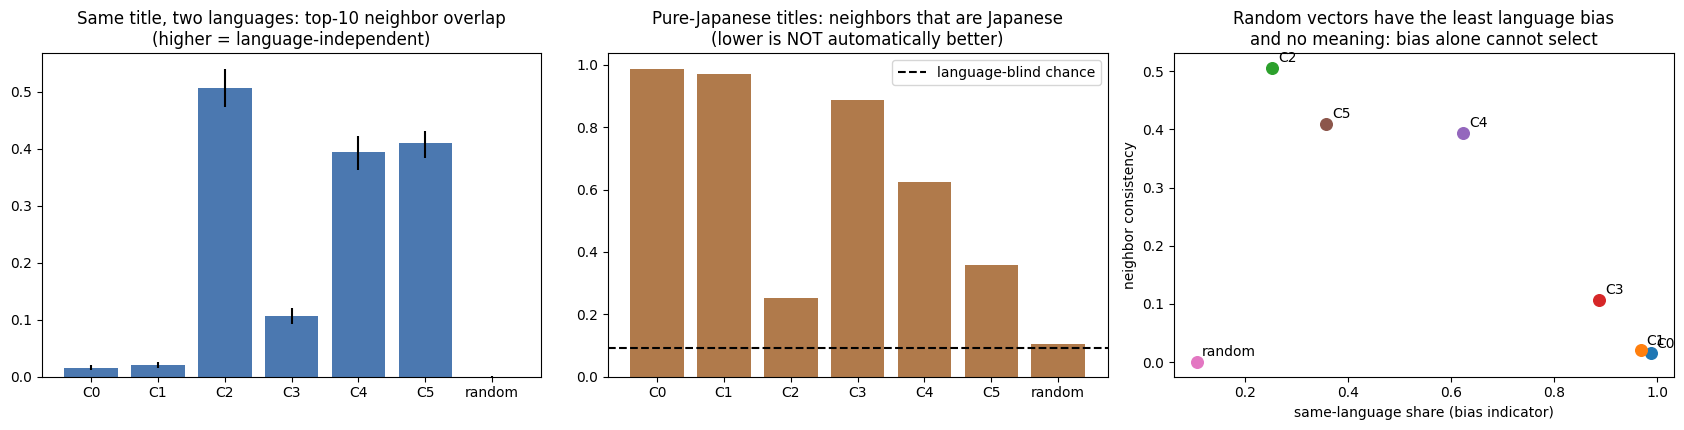

In [4]:
order = ["C0", "C1", "C2", "C3", "C4", "C5", "random"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
cons = [C[n]["cross_lingual_neighbor_consistency"]["overlap"] for n in order]
axes[0].bar(order, [c["mean"] for c in cons], yerr=[[c["mean"] - c["lo"] for c in cons], [c["hi"] - c["mean"] for c in cons]], color="#4b78b0")
axes[0].set_title("Same title, two languages: top-10 neighbor overlap\n(higher = language-independent)")
hom = [C[n]["homophily"]["ja_pure"]["observed"] for n in order]
axes[1].bar(order, hom, color="#b07a4b"); axes[1].axhline(C["C0"]["homophily"]["ja_pure"]["chance"], ls="--", c="k", label="language-blind chance")
axes[1].set_title("Pure-Japanese titles: neighbors that are Japanese\n(lower is NOT automatically better)"); axes[1].legend()
for n in order:
    axes[2].scatter(C[n]["homophily"]["ja_pure"]["observed"], C[n]["cross_lingual_neighbor_consistency"]["overlap"]["mean"], s=70)
    axes[2].annotate(n, (C[n]["homophily"]["ja_pure"]["observed"], C[n]["cross_lingual_neighbor_consistency"]["overlap"]["mean"]), xytext=(4, 4), textcoords="offset points")
axes[2].set_xlabel("same-language share (bias indicator)"); axes[2].set_ylabel("neighbor consistency")
axes[2].set_title("Random vectors have the least language bias\nand no meaning: bias alone cannot select")
fig.tight_layout(); fig.savefig(FIG / "candidates.png", dpi=110); plt.show()

## 3. Robustness of the ranking

In [5]:
rows = []
for n, c in C.items():
    s = c["consistency_sensitivity"]
    rows.append({"candidate": NAMES[n], "k=10 (rule)": ci(c["cross_lingual_neighbor_consistency"]["overlap"]),
                 "k=5": ci(s["k5"]["overlap"]), "k=20": ci(s["k20"]["overlap"]),
                 "pool without any parallel node": ci(s["neighbor_pool_without_any_parallel_node_k10"]["overlap"])})
display(pd.DataFrame(rows).set_index("candidate"))
print("The ordering C2 > C5 ~ C4 > C3 >> C1 ~ C0 holds at k=5, 10, 20 and when every parallel title is removed from the neighbor pool.")

,k=10 (rule),k=5,k=20,pool without any parallel node
candidate,,,,
C0 MiniLM raw (baseline),"0.016 [0.011, 0.020]","0.013 [0.008, 0.017]","0.020 [0.015, 0.025]","0.006 [0.003, 0.009]"
C1 centroid removal,"0.021 [0.015, 0.026]","0.015 [0.009, 0.021]","0.027 [0.021, 0.033]","0.012 [0.008, 0.017]"
C2 MiniLM on English titles,"0.506 [0.473, 0.540]","0.498 [0.466, 0.532]","0.524 [0.493, 0.559]","0.504 [0.473, 0.539]"
C3 multilingual-e5-small,"0.107 [0.092, 0.121]","0.103 [0.086, 0.121]","0.116 [0.103, 0.130]","0.117 [0.103, 0.133]"
C4 paraphrase-multilingual,"0.394 [0.362, 0.421]","0.357 [0.327, 0.386]","0.408 [0.379, 0.436]","0.391 [0.359, 0.418]"
C5 LaBSE,"0.410 [0.384, 0.431]","0.390 [0.365, 0.418]","0.445 [0.421, 0.469]","0.404 [0.377, 0.427]"
control: random vectors,"0.000 [0.000, 0.001]","0.000 [0.000, 0.000]","0.001 [0.000, 0.001]","0.000 [0.000, 0.001]"
control: shuffled-label centroids,"0.016 [0.012, 0.021]","0.013 [0.008, 0.018]","0.020 [0.015, 0.025]","0.006 [0.003, 0.009]"


The ordering C2 > C5 ~ C4 > C3 >> C1 ~ C0 holds at k=5, 10, 20 and when every parallel title is removed from the neighbor pool.


## 4. Pre-registered selection

In [6]:
print("eligible:", sel["eligible"]); print("ineligible:", sel["ineligible_reasons"])
print("winner:", sel["winner"], "| replaces baseline:", sel["replaced"], "| gain vs baseline:", round(sel["gain_vs_baseline"], 3))
print("homophily and platform mixing used in selection:", sel["homophily_and_mixing_used_in_selection"])
t = C["C2"]["encoding"]
print("translation provenance:", t["translation_provenance"]["by_source"])
print("machine-translation quality on 599 platform-translated pairs:", t["mt_quality_on_parallel_pairs"])

eligible: ['C2', 'C3', 'C4', 'C5']
ineligible: {'C1': ['G2 translation MRR not above 0.25 and 10x the random control']}
winner: C2 | replaces baseline: True | gain vs baseline: 0.49
homophily and platform mixing used in selection: False
translation provenance: {'identity': 22037, 'machine': 1561, 'parenthetical': 655, 'untranslated': 44}
machine-translation quality on 599 platform-translated pairs: {'exact_match_after_normalization': 0.21035058430717862, 'mean_cosine_to_reference': 0.6987225413322449, 'mean_cosine_to_shuffled_reference': 0.16073952615261078, 'median_cosine_to_reference': 0.7720111012458801, 'pairs': 599}


## 5. Maps before and after (all 24,297 nodes)

In [7]:
rows = []
for tag, run in maps["runs"].items():
    for m in ("pca", "umap", "tsne"):
        mm = run["maps"][m]
        rows.append({"map": f"{tag} / {m}", "ja-pure in Japanese-only 2D neighborhood": mm["island_index_ja_pure_2d"],
                     "ja-pure same-language share (2D)": mm["homophily_2d"]["ja_pure"]["observed"],
                     "fidelity top-10, ja-pure": mm["fidelity_top10_by_class"]["ja_pure"],
                     "fidelity top-10, English": mm["fidelity_top10_by_class"]["en"]})
display(pd.DataFrame(rows).set_index("map").style.format("{:.3f}"))
rows = []
for tag, q in (("v1 raw titles", q1), ("v2 translated titles", q2)):
    for m in ("pca", "umap", "tsne"):
        e = q["projections"][m + "-seed17"]
        rows.append({"map": f"{tag} / {m}", "top-10 kept": e["preservation_top10_any"], "cross-platform kept": e["preservation_top10_cross_platform"],
                     "trust": e["trustworthiness"], "continuity": e["continuity"]})
display(pd.DataFrame(rows).set_index("map").style.format("{:.3f}"))
print("v2 stability:", {m: [(s["seeds"], round(s["procrustes_disparity"], 2), round(s["top10_2d_neighbor_overlap"], 3)) for s in l] for m, l in q2["stability"].items()})

,ja-pure in Japanese-only 2D neighborhood,ja-pure same-language share (2D),"fidelity top-10, ja-pure","fidelity top-10, English"
map,,,,
v1_minilm_raw_title / pca,0.936,0.973,0.117,0.029
v1_minilm_raw_title / umap,0.977,0.988,0.244,0.293
v1_minilm_raw_title / tsne,0.977,0.991,0.484,0.483
v2_minilm_translated_title / pca,0.000,0.144,0.052,0.032
v2_minilm_translated_title / umap,0.004,0.190,0.280,0.302
v2_minilm_translated_title / tsne,0.022,0.221,0.471,0.485


,top-10 kept,cross-platform kept,trust,continuity
map,,,,
v1 raw titles / pca,0.035,0.027,0.700,0.840
v1 raw titles / umap,0.289,0.247,0.916,0.935
v1 raw titles / tsne,0.483,0.356,0.974,0.931
v2 translated titles / pca,0.034,0.017,0.693,0.834
v2 translated titles / umap,0.302,0.272,0.915,0.922
v2 translated titles / tsne,0.486,0.390,0.974,0.927


v2 stability: {'tsne-random': [([18, 19], 0.04, 0.773)], 'umap': [([17, 18], 0.79, 0.298), ([17, 19], 0.75, 0.301), ([18, 19], 0.89, 0.296)]}


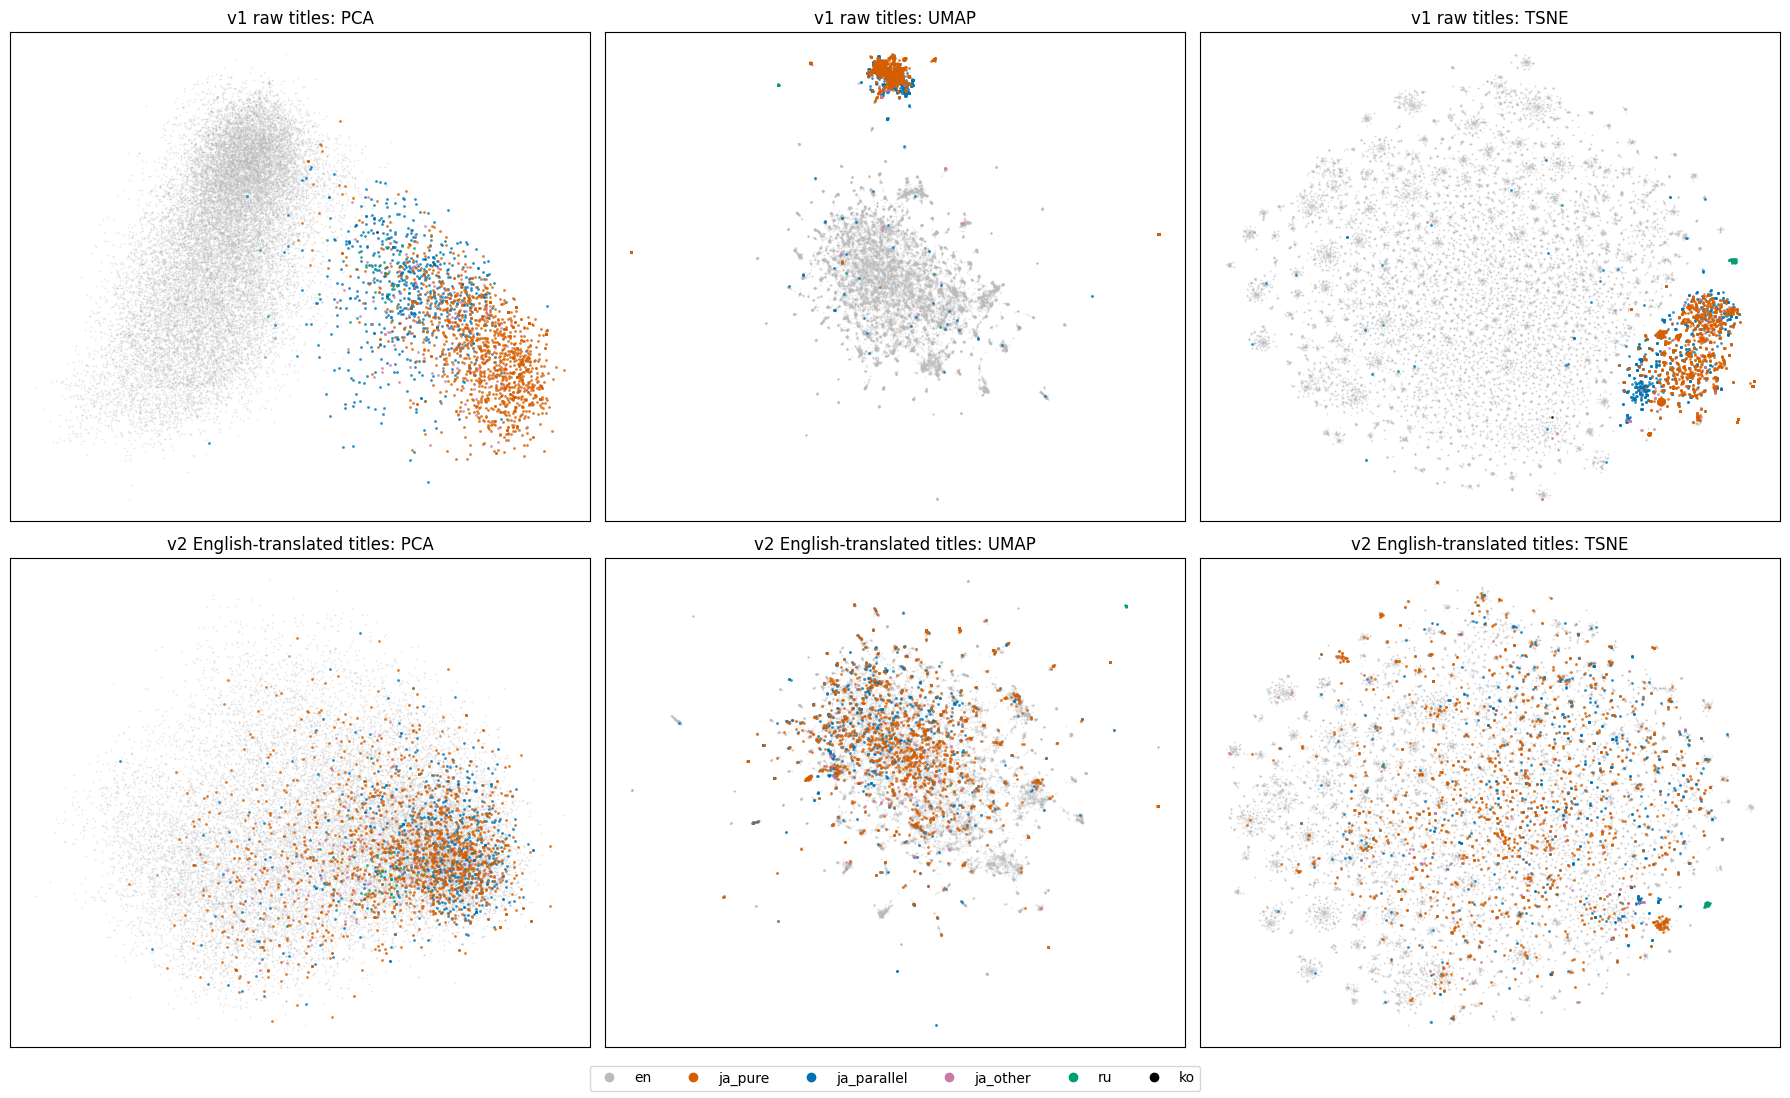

Colour = language class of the original title (points only; no titles).


In [8]:
from research.language_bias import languages as L
from research.unified_map import full_quality as fq
nodes = fq.load_nodes()
cls = np.array([L.language_class(n["title"]) for n in nodes])
pal = {"en": "#bbbbbb", "ja_pure": "#D55E00", "ja_parallel": "#0072B2", "ja_other": "#CC79A7", "ru": "#009E73", "ko": "#000000"}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for r, (label, run) in enumerate((("v1 raw titles", "full-v1"), ("v2 English-translated titles", "full-v2"))):
    for c, m in enumerate(("pca", "umap", "tsne")):
        xy = np.load(ROOT / f"private-learning/unified-map/{run}/projections/{m}-seed17.npy")
        ax = axes[r, c]
        for k in ("en", "ja_parallel", "ja_other", "ru", "ko", "ja_pure"):     # draw the Japanese groups on top
            mask = cls == k
            ax.scatter(xy[mask, 0], xy[mask, 1], s=1.5 if k == "en" else 4, alpha=0.35 if k == "en" else 0.8, c=pal[k], linewidths=0)
        ax.set_title(f"{label}: {m.upper()}"); ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=pal[k], label=k) for k in pal]
fig.legend(handles=handles, loc="lower center", ncol=6); fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "maps-by-language.png", dpi=100); plt.show()
print("Colour = language class of the original title (points only; no titles).")

## Limits

- The benchmark titles already carry English, so alignment on them may overstate gains on pure-Japanese titles.
- Machine translation is noisy (21% exact matches, mean cosine 0.70 to the platform's own English); degraded-tier titles can retrieve arbitrary neighbors.
- No algorithm labels exist for Japanese nodes. Concept coherence is a weak proxy (lift about 1.1, only 40% of neighbor slots tagged).
- Russian and Korean titles are not translated and still cluster by language.
- Remaining Japanese neighborhoods in the maps are partly real (same-contest tutorial and heuristic-contest pages with identical titles) and not all language bias.